# 03. Đào sâu và kiểm chứng: nghiên cứu khác làm gì, bộ quy tắc có đáng tin không

> Đọc sau `00` (hiểu dataset) và `02` (data mining, chọn bộ phát hiện D1/D2/D4).

Notebook 02 đi đến bộ quy tắc **D1 im lặng + D2 gửi dồn + D4 lệch âm**, bắt 11/11 cửa sổ sự cố với 0 báo giả. Notebook này trả lời năm câu hỏi còn bỏ ngỏ:

1. Đã có ai phân tích DAD kỹ hơn chưa, họ làm gì?
2. Bài báo dùng ML trên DAD đạt accuracy 0,9998. Con số đó có đáng tin không?
3. Ngưỡng D4 có bị "khớp" quá mức vào chính dữ liệu dùng để chấm không?
4. Hệ thống có tự **điều tra** được không (loại sự cố, mức độ, phạm vi)?
5. Khi replay nhanh cho demo, các con số thời gian đổi thế nào?

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(os.path.join("..", "src")))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score
from dad_loader import load_all
import dad_mining as dm

RAW = os.path.abspath(os.path.join("..", "..")); CACHE = os.path.abspath(os.path.join("..", "data", "processed"))
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]; INK = "#0b0b0b"; INK2 = "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "grid.color": "#c3c2b7",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK2,
                     "text.color": INK, "axes.labelcolor": INK2})
packets, pubs = load_all(RAW, CACHE)
pubs = dm.add_baseline(pubs)
nodes = dm.node_slots(pubs)
gt = dm.ground_truth(pubs)
labeled = gt[gt.kind == "labeled"]
print("bản tin:", len(pubs), "| cửa sổ sự cố:", len(gt), "(", len(labeled), "có nhãn )")

bản tin: 32288 | cửa sổ sự cố: 11 ( 6 có nhãn )


## 1. Nghiên cứu khác đã làm gì với DAD

Tra cứu qua Semantic Scholar (20 bài trích dẫn bài báo DAD, tính đến 10/2026) và tìm kiếm thêm theo chủ đề:

| Công trình | Làm gì | Liên quan thế nào |
|---|---|---|
| Vigoya et al., *Sensors* 2020 (bài gốc) | Tạo dataset, mô tả thống kê gói và flow | Không đánh giá bộ phát hiện nào |
| Vigoya et al., *Electronics* 2021, 10(22), 2857 | 5 mô hình ML (LR, Naive Bayes, Random Forest, AdaBoost, SVM) trên đặc trưng flow; RF và AdaBoost đạt accuracy 0,9998 | **Bài duy nhất đánh giá phát hiện trên DAD.** Mục 2 kiểm tra lại cách làm |
| *Thermal Management in Large Data Centres: Security Threats and Mitigation* (2021) | Phân tích tấn công vào hệ thống đo nhiệt và làm mát data center ("thermal attack"), đề xuất phát hiện đa biến + chỉ số sức khoẻ | **Cùng lĩnh vực.** Xác nhận kịch bản "dữ liệu nhiệt bị sửa → hệ thống làm mát sai → sập" là mối đe doạ có thật |
| Các bài tổng quan dataset IoT (IEEE COMST 2023, Computers & Security 2023, ACM CSUR 2025) | Liệt kê DAD trong danh mục dataset | Không phân tích sâu |
| Nghiên cứu phát hiện *false data injection* trên mạng cảm biến (ví dụ *Sensors* 2024, 24(5), 1643) | Nhóm cảm biến theo tương quan không gian–thời gian, mô hình ARIMA trong nhóm, đánh dấu node lệch | Cùng ý tưởng "so với nhóm"; trên DAD không dùng được vì bộ sinh làm InRow 13 lệch nhóm cả ngày (02, mục 7.3) |

**Kết luận:** chưa thấy công trình nào phân tích DAD ở mức **giá trị nhiệt độ** và **nhịp gửi** như notebook 02. Bài duy nhất có đánh giá phát hiện dùng đặc trưng định danh và thời gian, và có vấn đề rò nhãn (mục 2).

## 2. Kiểm chứng kết quả ML của bài *Electronics* 2021

Bài báo chọn được 12 đặc trưng tốt nhất: `hour_sin`, `hour_cos`, `d_flow`, `ip.src_10.6.56.41`, `ClientId_131`…`134`, `weekday_Wednesday`…`Saturday`. Tức là: **giờ trong ngày, thứ trong tuần, IP và mã của InRow 13**. Không có đặc trưng nào về giá trị nhiệt độ hay nhịp gửi. Họ chấm bằng *stratified k-fold* chia **ngẫu nhiên**.

Vấn đề: tấn công trong DAD chỉ đến từ InRow 13, vào thứ Tư đến thứ Bảy, theo khung giờ cố định. Một mô hình học thuộc "InRow 13 + thứ + giờ" sẽ đạt điểm gần tuyệt đối mà **không hề phát hiện hành vi bất thường**. Chia ngẫu nhiên thì các bản tin cùng một đợt tấn công nằm ở cả tập train lẫn test, nên lỗi này không lộ ra.

**Thí nghiệm:** huấn luyện Random Forest trên từng bản tin PUBLISH, so 2 cách chia dữ liệu:
- **CV ngẫu nhiên** (như bài báo);
- **giữ lại một ngày** (*leave-one-day-out*): train trên 6 ngày, test trên ngày còn lại. Đây là cách gần với thực tế: mô hình phải nhận ra tấn công vào một ngày nó chưa thấy.

So 3 cách tiếp cận: đặc trưng kiểu bài báo, đặc trưng hành vi (khoảng cách tới bản tin trước, độ lệch so với baseline, D4), và bộ quy tắc D2 + D4 không cần huấn luyện.

In [2]:
u = pubs.merge(nodes[["inrow", "slot", "neg_count6", "mean_dev6"]], on=["inrow", "slot"], how="left")
h = u.time.dt.hour + u.time.dt.minute / 60
X_paper = pd.DataFrame({"hour_sin": np.sin(2 * np.pi * h / 24), "hour_cos": np.cos(2 * np.pi * h / 24), "ip_41": (u.src == "10.6.56.41").astype(int)})
for d in ["wed", "thu", "fri", "sat"]: X_paper["weekday_" + d] = (u.day == d).astype(int)
for c in ["131", "132", "133", "134"]: X_paper["client_" + c] = (u.client_id == c).astype(int)
X_beh = pd.DataFrame({"gap_s": u.gap_s.fillna(dm.PERIOD_S), "new_conn": u.new_conn.astype(int), "dev": u.dev.fillna(0),
                      "neg_count6": u.neg_count6.fillna(0), "mean_dev6": u.mean_dev6.fillna(0)})
y = u.label.astype(int).values
rule = (((u.gap_s < dm.BURST_FACTOR * dm.PERIOD_S) & ~u.new_conn) | (u.neg_count6 >= dm.DEV_K)).astype(int).values
rf = lambda: RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1, class_weight="balanced")

rows = []
for name, X in [("RF, đặc trưng kiểu bài báo", X_paper), ("RF, đặc trưng hành vi", X_beh)]:
    yp = cross_val_predict(rf(), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0))
    rows.append((name, "CV ngẫu nhiên", f1_score(y, yp), precision_score(y, yp), recall_score(y, yp)))
    for d in ["wed", "thu", "fri", "sat"]:
        tr = (u.day != d).values
        yp = rf().fit(X[tr], y[tr]).predict(X[~tr])
        rows.append((name, f"giữ lại {d}", f1_score(y[~tr], yp), precision_score(y[~tr], yp, zero_division=0), recall_score(y[~tr], yp)))
rows.append(("Quy tắc D2 + D4 (không huấn luyện)", "cả tuần", f1_score(y, rule), precision_score(y, rule), recall_score(y, rule)))
for d in ["wed", "thu", "fri", "sat"]:
    m = (u.day == d).values
    rows.append(("Quy tắc D2 + D4 (không huấn luyện)", f"giữ lại {d}", f1_score(y[m], rule[m]), precision_score(y[m], rule[m]), recall_score(y[m], rule[m])))
res = pd.DataFrame(rows, columns=["cách làm", "cách chia", "F1", "precision", "recall"]).round(3)
res.pivot(index="cách làm", columns="cách chia", values="F1")[["CV ngẫu nhiên", "cả tuần", "giữ lại wed", "giữ lại thu", "giữ lại fri", "giữ lại sat"]]

cách chia,CV ngẫu nhiên,cả tuần,giữ lại wed,giữ lại thu,giữ lại fri,giữ lại sat
cách làm,,,,,,
Quy tắc D2 + D4 (không huấn luyện),NaN,0.882,0.917,0.839,0.854,0.907
"RF, đặc trưng hành vi",0.95,NaN,0.866,0.755,0.872,0.875
"RF, đặc trưng kiểu bài báo",0.99,NaN,0.000,0.000,0.000,0.000


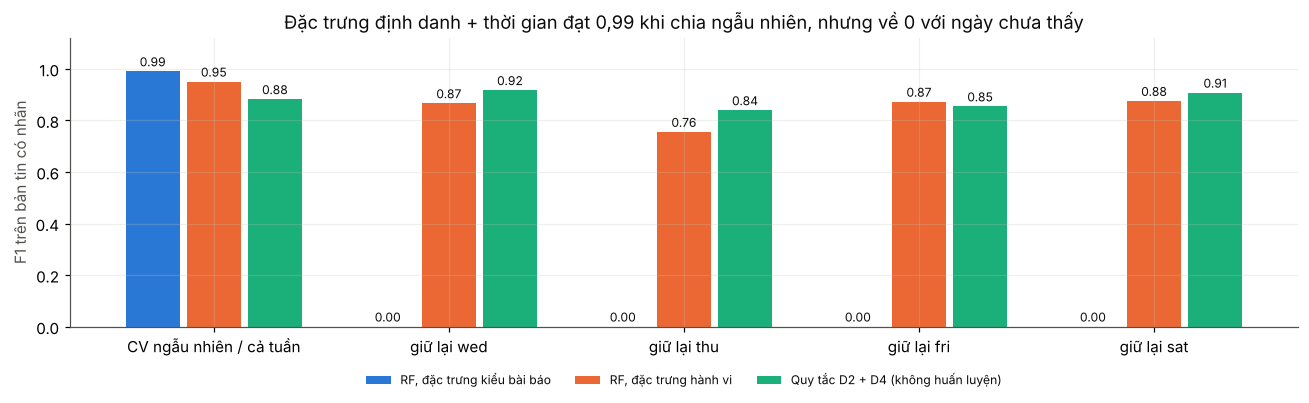

In [3]:
fig, ax = plt.subplots(figsize=(12, 3.8))
names = ["RF, đặc trưng kiểu bài báo", "RF, đặc trưng hành vi", "Quy tắc D2 + D4 (không huấn luyện)"]
splits = ["CV ngẫu nhiên / cả tuần", "giữ lại wed", "giữ lại thu", "giữ lại fri", "giữ lại sat"]
w = 0.26
for i, nm in enumerate(names):
    r = res[res["cách làm"] == nm].set_index("cách chia").F1
    vals = [r.get("CV ngẫu nhiên", r.get("cả tuần"))] + [r[s] for s in splits[1:]]
    bars = ax.bar(np.arange(5) + (i - 1) * w, vals, width=w - 0.03, color=SERIES[i], label=nm)
    for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", fontsize=8, color=INK)
ax.set_xticks(range(5)); ax.set_xticklabels(splits); ax.set_ylim(0, 1.12); ax.set_ylabel("F1 trên bản tin có nhãn")
ax.legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
ax.set_title("Đặc trưng định danh + thời gian đạt 0,99 khi chia ngẫu nhiên, nhưng về 0 với ngày chưa thấy")
plt.tight_layout(); plt.show()

**Kết luận mục 2**
- Đặc trưng kiểu bài báo cho **F1 ≈ 0,99 khi chia ngẫu nhiên**, nhưng **F1 = 0 ở cả 4 ngày** khi phải dự đoán một ngày chưa thấy. Mô hình học thuộc *lịch tấn công*, không học *dấu hiệu tấn công*. Con số 0,9998 của bài báo nhiều khả năng là kết quả của **rò nhãn** (label leakage) qua đặc trưng định danh và thời gian.
- Đặc trưng **hành vi** giữ được F1 0,76–0,88 trên ngày chưa thấy.
- **Bộ quy tắc D2 + D4 không cần huấn luyện** đạt F1 0,84–0,92 từng ngày, ngang hoặc tốt hơn ML, lại giải thích được và viết được bằng MongoDB aggregation.
- Lưu ý công bằng: thí nghiệm này tái tạo **tinh thần** cách làm của bài báo (cùng nhóm đặc trưng, cùng kiểu CV) trên mức bản tin, chưa phải tái tạo y hệt pipeline của họ (họ làm trên flow, có SMOTE, chọn đặc trưng bằng RFE).
- **Ý nghĩa cho bài thi:** đây là luận điểm tốt để trình bày: "vì sao chọn quy tắc dựa trên hành vi thay vì ML", có thực nghiệm chứng minh.

## 3. Ngưỡng D4 có bị "khớp" quá mức không?

D4 có 3 tham số: ngưỡng lệch **T** (°C), cửa sổ **W** (số chu kỳ), số chu kỳ tối thiểu **K**. Notebook 02 chọn T = 0,8, W = 6, K = 3 và chấm trên cùng dữ liệu. Hai cách kiểm tra:

**3.1 Quét toàn bộ lưới tham số.** Nếu chỉ một điểm duy nhất cho kết quả tốt thì đó là khớp may mắn; nếu cả một vùng đều tốt thì quy tắc ổn định.

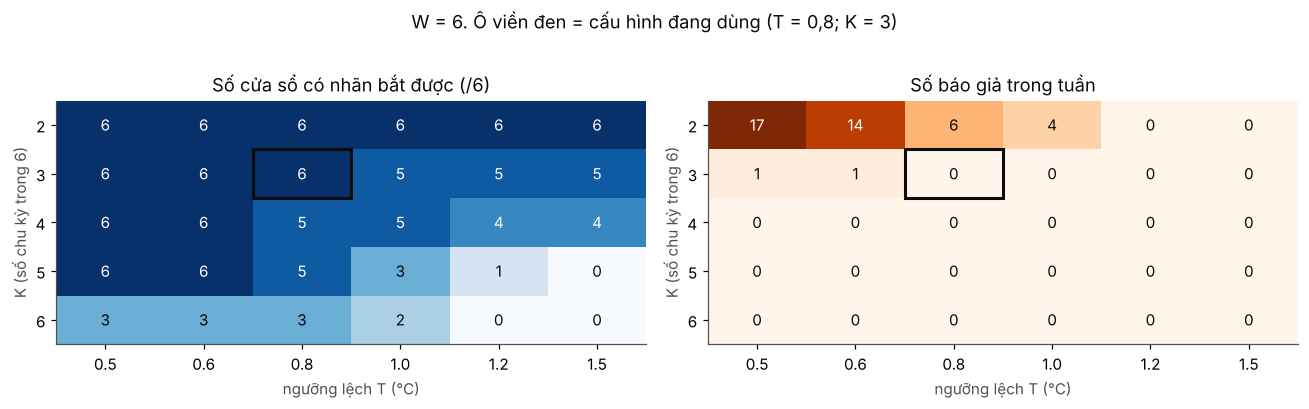

Cấu hình bắt 6/6 và 0 báo giả (W = 6): [(2, 1.2), (2, 1.5), (3, 0.8), (4, 0.5), (4, 0.6), (5, 0.5), (5, 0.6)]


In [4]:
def d4_alarm(T, K, W, n=nodes):
    c = (n.dev < -T).groupby(n.inrow).transform(lambda s: s.rolling(W).sum())
    s = n[c >= K]; return pd.DataFrame({"inrow": s.inrow, "t": s.slot + pd.Timedelta("5min")})
TS = [0.5, 0.6, 0.8, 1.0, 1.2, 1.5]; KS = [2, 3, 4, 5, 6]
caught = pd.DataFrame(index=KS, columns=TS, dtype=float); fps = caught.copy()
for K in KS:
    for T in TS:
        ev, dl = dm.evaluate(d4_alarm(T, K, 6), gt)
        caught.loc[K, T] = dl[labeled.index].notna().sum(); fps.loc[K, T] = (~ev.dung).sum()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, M, title, cmap in [(axes[0], caught, "Số cửa sổ có nhãn bắt được (/6)", "Blues"), (axes[1], fps, "Số báo giả trong tuần", "Oranges")]:
    ax.imshow(M.values.astype(float), cmap=cmap, aspect="auto", vmin=0, vmax=max(6, M.values.max()))
    for i in range(len(KS)):
        for j in range(len(TS)):
            v = int(M.values[i, j]); ax.text(j, i, v, ha="center", va="center", fontsize=10,
                                             color="white" if v > 0.6 * max(6, M.values.max()) else INK)
    ax.set_xticks(range(len(TS))); ax.set_xticklabels([f"{t}" for t in TS]); ax.set_yticks(range(len(KS))); ax.set_yticklabels(KS)
    ax.set_xlabel("ngưỡng lệch T (°C)"); ax.set_ylabel("K (số chu kỳ trong 6)"); ax.set_title(title); ax.grid(False)
    ax.add_patch(plt.Rectangle((TS.index(0.8) - 0.5, KS.index(3) - 0.5), 1, 1, fill=False, ec=INK, lw=2))
plt.suptitle("W = 6. Ô viền đen = cấu hình đang dùng (T = 0,8; K = 3)", y=1.02); plt.tight_layout(); plt.show()
ok = [(K, T) for K in KS for T in TS if caught.loc[K, T] == 6 and fps.loc[K, T] == 0]
print("Cấu hình bắt 6/6 và 0 báo giả (W = 6):", ok)

- Có một **dải chéo** các cấu hình hoàn hảo: K = 2 với T ≥ 1,2; K = 3 với T = 0,8; K = 4–5 với T = 0,5–0,6. Không phải một điểm đơn lẻ, nhưng dải **hẹp**.
- Cấu hình đang dùng (K = 3, T = 0,8) là ô hoàn hảo **đứng một mình**: tăng T lên 1,0 thì sót một cửa sổ, giảm K xuống 2 thì có báo giả. Còn K = 4–5 với T = 0,5–0,6 tạo thành **một khối 2×2** toàn ô hoàn hảo, nên chịu nhiễu tốt hơn.
- **Đánh đổi:** K = 4, T = 0,6 có độ trễ trung vị **22 phút** (tối đa 39), còn K = 3, T = 0,8 là **15 phút** (tối đa 28). K = 5 chậm hẳn (trung vị 47 phút).
- **Đề xuất:** demo giữ **K = 3, T = 0,8** (nhanh, đã kiểm chứng ở 3.2). Hệ thống thật, nơi báo giả tốn kém hơn, cân nhắc **K = 4, T = 0,6**. Để cả hai thành tham số cấu hình.

**3.2 Chọn ngưỡng trên quá khứ, kiểm tra trên tương lai.** Chỉ dùng dữ liệu **đến hết thứ Năm** (2 cửa sổ có nhãn) để chọn tham số, rồi kiểm tra trên **thứ Sáu và thứ Bảy** (4 cửa sổ chưa thấy):

In [5]:
cut = pd.Timestamp("2019-10-24 22:00", tz="UTC")              # hết thứ Năm theo giờ Tây Ban Nha
tr_w, te_w = labeled[labeled.start < cut], labeled[labeled.start >= cut]
rows = []
for W in [4, 6, 8, 12]:
    for K in range(2, min(W, 6) + 1):
        for T in TS:
            a = d4_alarm(T, K, W)
            if a.empty: continue
            ev, dl = dm.evaluate(a, gt)
            rows.append(dict(W=W, K=K, T=T, train_bắt=int(dl[tr_w.index].notna().sum()), train_báo_giả=int(((~ev.dung) & (ev.start < cut)).sum()),
                             train_trễ=dl[tr_w.index].mean(), test_bắt=int(dl[te_w.index].notna().sum()),
                             test_báo_giả=int(((~ev.dung) & (ev.start >= cut)).sum()), test_trễ=dl[te_w.index].mean()))
r = pd.DataFrame(rows)
chosen = r[(r.train_bắt == len(tr_w)) & (r.train_báo_giả == 0)].sort_values(["train_trễ", "T"])
print(f"{len(chosen)} cấu hình hoàn hảo trên train; kết quả của chúng trên test ({len(te_w)} cửa sổ):")
print(chosen[["test_bắt", "test_báo_giả"]].value_counts().rename("số cấu hình").to_string())
chosen.head(5).round(1)

28 cấu hình hoàn hảo trên train; kết quả của chúng trên test (4 cửa sổ):
test_bắt  test_báo_giả
4         0               28


,W,K,T,train_bắt,train_báo_giả,train_trễ,test_bắt,test_báo_giả,test_trễ
6,4,3,0.5,2,0,12.4,4,0,19.0
7,4,3,0.6,2,0,12.4,4,0,19.0
4,4,2,1.2,2,0,12.4,4,0,17.8
21,6,2,1.2,2,0,12.4,4,0,17.8
48,8,2,1.2,2,0,12.4,4,0,14.0


- Mọi cấu hình đạt hoàn hảo trên thứ Hai đến thứ Năm đều **bắt đủ 4/4 cửa sổ thứ Sáu–thứ Bảy, không báo giả** (bảng trên). Quy tắc **tổng quát hoá được sang ngày chưa thấy**, khác với mô hình ML ở mục 2.
- Giới hạn: chỉ có 2 cửa sổ để chọn và 4 cửa sổ để kiểm tra, từ cùng một kẻ tấn công. Đủ để nói "không khớp may mắn", chưa đủ để nói về hiệu năng tổng quát.

## 4. Biến thể D4 theo từng cảm biến

D4 trong notebook 02 gộp 4 cảm biến của một InRow. Ngoài thực tế (bài báo, Hình 3), các cảm biến trong một tủ **không** đi cùng nhau như trong DAD, nên cần chạy D4 cho **từng cảm biến** riêng. Đánh giá biến thể này trên DAD:

In [6]:
s = pubs.sort_values(["client_id", "ts"]).copy()
s["c6"] = (s.dev < -dm.DEV_T).groupby(s.client_id).transform(lambda x: x.rolling(dm.DEV_W).sum())
per_sensor = pd.DataFrame({"inrow": s[s.c6 >= dm.DEV_K].inrow, "t": s[s.c6 >= dm.DEV_K].time_utc})
ev_s, dl_s = dm.evaluate(per_sensor, gt)
ev_n, dl_n = dm.evaluate(dm.alarms(pubs, nodes)["D4 lệch âm 3/6 (mới)"], gt)
pd.DataFrame({"D4 gộp theo InRow (trễ, phút)": dl_n[labeled.index].values, "D4 theo từng cảm biến (trễ, phút)": dl_s[labeled.index].values},
             index=labeled.local.values).round(1)

,"D4 gộp theo InRow (trễ, phút)","D4 theo từng cảm biến (trễ, phút)"
Wed 23/10 04:10–06:15,14.9,10.0
Thu 24/10 03:05–03:22,14.9,6.1
Fri 25/10 06:00–06:25,14.9,3.9
Fri 25/10 14:27–16:22,27.8,25.0
Sat 26/10 06:00–06:25,9.8,3.3
Sat 26/10 14:26–16:21,18.6,15.0


In [7]:
print("Gộp theo InRow: báo giả", int((~ev_n.dung).sum()), "| theo từng cảm biến: báo giả", int((~ev_s.dung).sum()))
print("Báo giả của bản theo cảm biến:"); ev_s[~ev_s.dung].assign(start=lambda d: d.start.dt.tz_convert("Europe/Madrid"))

Gộp theo InRow: báo giả 0 | theo từng cảm biến: báo giả 1
Báo giả của bản theo cảm biến:


,inrow,start,end,n,dung
6,25,2019-10-23 07:40:11.478090048+02:00,2019-10-23 05:45:11.580305099+00:00,2,False


- Theo từng cảm biến **nhanh hơn rõ rệt** (sáng thứ Sáu: 4 phút so với 15 phút). Đổi lại có **1 báo giả** trong tuần (InRow 25, sáng thứ Tư).
- **Đề xuất:** chạy **cả hai**. Bản theo cảm biến làm cảnh báo sớm (warning); bản gộp theo InRow để xác nhận (critical). Nếu chỉ 1 cảm biến lệch mà 3 cảm biến kia bình thường, nhiều khả năng là **hỏng cảm biến**, không phải tấn công vào cả tủ. Đây là thông tin hữu ích cho bước điều tra.

## 5. Tự động điều tra: hệ thống trả lời được gì về mỗi sự cố

Tiêu chí chấm của cuộc thi đòi hỏi **điều tra**, không chỉ phát hiện. Với mỗi cửa sổ sự cố, chỉ từ dữ liệu telemetry, hệ thống có thể tự tính:

In [8]:
rows = []
for i, g in gt.iterrows():
    w = pubs[(pubs.inrow == g.inrow) & (pubs.time_utc >= g.start - pd.Timedelta("5min")) & (pubs.time_utc <= g.end + pd.Timedelta("5min"))]
    nn = nodes[(nodes.inrow == g.inrow) & (nodes.slot >= g.start.floor("5min")) & (nodes.slot <= g.end)]
    lost = int(((w.gap_s / dm.PERIOD_S).round() - 1).clip(lower=0)[w.gap_s > dm.SILENCE_FACTOR * dm.PERIOD_S].sum())
    extra = int(((w.gap_s < dm.BURST_FACTOR * dm.PERIOD_S) & ~w.new_conn).sum())
    drops = nn.dev[nn.dev < -dm.DEV_T]
    kind = " + ".join(k for k, c in [("chặn gói", lost > 0), ("chèn gói", extra > 0), ("sửa giá trị", len(drops) >= dm.DEV_K)] if c)
    rows.append({"cửa sổ": g.local, "đáp án": "không nhãn (chặn gói)" if g.kind == "interception" else "có nhãn",
                 "hệ thống suy ra": kind, "bản tin mất (tổng 4 cảm biến)": lost, "bản tin thừa (tổng 4 cảm biến)": extra, "chu kỳ bị trừ": len(drops),
                 "mức trừ hay gặp": f"{-drops.round().mode().iloc[0]:.0f} °C" if len(drops) else "", "số cảm biến": w.client_id.nunique()})
inv = pd.DataFrame(rows); inv

,cửa sổ,đáp án,hệ thống suy ra,bản tin mất (tổng 4 cảm biến),bản tin thừa (tổng 4 cảm biến),chu kỳ bị trừ,mức trừ hay gặp,số cảm biến
0,Tue 22/10 00:15–00:55,không nhãn (chặn gói),chặn gói,16,0,0,,4
1,Tue 22/10 01:25–02:25,không nhãn (chặn gói),chặn gói,24,0,0,,4
2,Wed 23/10 04:10–06:15,có nhãn,sửa giá trị,0,0,17,2 °C,4
3,Thu 24/10 03:05–03:22,có nhãn,chèn gói + sửa giá trị,0,56,3,2 °C,4
4,Thu 24/10 23:03–00:00,không nhãn (chặn gói),chặn gói,40,0,0,,4
5,Fri 25/10 03:25–05:00,không nhãn (chặn gói),chặn gói,60,0,0,,4
6,Fri 25/10 06:00–06:25,có nhãn,chèn gói + sửa giá trị,0,96,6,2 °C,4
7,Fri 25/10 14:27–16:22,có nhãn,sửa giá trị,0,0,15,2 °C,4
8,Sat 26/10 03:00–05:00,không nhãn (chặn gói),chặn gói,40,0,0,,4
9,Sat 26/10 06:00–06:25,có nhãn,chèn gói + sửa giá trị,0,96,6,2 °C,4


- Mọi cửa sổ không nhãn đều được suy ra là **chặn gói**, có kèm số bản tin mất (tổng của 4 cảm biến).
- Cửa sổ có nhãn tách được thành **sửa giá trị** (thứ Tư, chiều thứ Sáu, chiều thứ Bảy) và **chèn gói** (thứ Năm, sáng thứ Sáu, sáng thứ Bảy). Các bản tin chèn cũng mang giá trị thấp, nên được ghi là "chèn gói + sửa giá trị". Điều này khớp với README ("trộn cả ba loại").
- **Mức trừ** ước lượng được (thường **2 °C**), và luôn là **4/4 cảm biến**, nên kết luận được là "tấn công vào node", không phải "hỏng cảm biến".
- **Dùng cho demo:** mỗi incident trong MongoDB lưu sẵn các trường này (loại, mất/thừa bao nhiêu, mức trừ, phạm vi). Datadog hiển thị chúng trong nội dung cảnh báo và trên dashboard. Đây là phần "Điều tra" của tiêu chí chấm.

## 6. Thời gian khi replay cho demo

Dữ liệu gốc 5 phút một bản tin. Demo cần tua nhanh. Bảng dưới đổi các mốc thời gian sang **thời gian demo**:

In [9]:
A = dm.alarms(pubs, nodes)
med = {k: float(np.nanmedian(dm.evaluate(A[k], gt)[1])) for k in ["D1 im lặng", "D2 gửi dồn"]}
items = {"chu kỳ gửi": 5.0, "D1 báo (trung vị)": med["D1 im lặng"], "D2 báo (trung vị)": med["D2 gửi dồn"],
         "D4 báo (trung vị)": float(np.nanmedian(dl_n[labeled.index])), "sự cố sửa giá trị thứ Tư (dài)": 125.0,
         "baseline cần làm nóng (288 bản tin)": 288 * 5.0, "một ngày dữ liệu": 1440.0}
tab = pd.DataFrame({"thời gian thật (phút)": items})
for k, f in [("tua ×60 (giây)", 60), ("tua ×288 (giây)", 288)]:
    tab[k] = (tab["thời gian thật (phút)"] * 60 / f).round(1)
tab

,thời gian thật (phút),tua ×60 (giây),tua ×288 (giây)
chu kỳ gửi,5.0,5.0,1.0
D1 báo (trung vị),7.5,7.5,1.6
D2 báo (trung vị),1.1,1.1,0.2
D4 báo (trung vị),14.9,14.9,3.1
sự cố sửa giá trị thứ Tư (dài),125.0,125.0,26.0
baseline cần làm nóng (288 bản tin),1440.0,1440.0,300.0
một ngày dữ liệu,1440.0,1440.0,300.0


- Ở tốc độ **×60**, D2 báo sau khoảng 1–1,5 giây, D1 sau 7,5 giây, D4 sau khoảng 15 giây; cả sự cố thứ Tư kéo dài khoảng 2 phút. Vừa vặn cho video demo.
- **Bẫy cần tránh:** D4 cần baseline 288 bản tin (1 ngày dữ liệu). Nếu khởi động replay ngay vào thứ Tư, baseline chưa có và D4 sẽ không báo. Cách xử lý: **nạp trước thứ Hai làm baseline** (ghi thẳng vào MongoDB, không cần tua), rồi mới replay đoạn có sự cố.
- Cửa sổ thời gian của monitor Datadog phải **co theo tốc độ tua** (ví dụ cửa sổ 30 phút thật thành 30 giây ở ×60). Nên tham số hoá `P` (chu kỳ sau khi tua) trong mọi truy vấn.

## 7. Tổng kết

| Câu hỏi | Trả lời |
|---|---|
| Có ai phân tích DAD sâu hơn chưa? | Chưa thấy. Bài ML duy nhất dùng đặc trưng định danh + thời gian |
| Accuracy 0,9998 có đáng tin? | Không: F1 về 0 khi gặp ngày chưa thấy (rò nhãn) |
| Bộ quy tắc có đáng tin? | Có, trong giới hạn của DAD: ổn định trên một dải tham số, tổng quát hoá sang ngày chưa thấy, F1 ngang/hơn ML |
| Nên chỉnh gì? | Demo giữ K = 3, T = 0,8; hệ thống thật cân nhắc K = 4, T = 0,6 (ổn định hơn, chậm hơn khoảng 7 phút); thêm D4 theo cảm biến làm cảnh báo sớm |
| Điều tra tự động được không? | Được: loại sự cố, số bản tin mất/thừa, mức trừ, phạm vi cảm biến |
| Demo cần lưu ý gì? | Nạp trước 1 ngày làm baseline; tham số hoá chu kỳ `P` theo tốc độ tua |

Đặc tả monitor cuối cùng cho cuộc thi: xem `monitoring/MONITOR_SPEC.md`.